In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Phase-space grid environment ready.")

NumPy version: 2.4.6
Phase-space grid environment ready.


In [2]:
# Spatial domain
L = 2 * np.pi

# Velocity domain
v_min = -6.0
v_max = 6.0

# Number of grid points
Nx = 64
Nv = 64

# Create grids
x = np.linspace(0, L, Nx, endpoint=False)
v = np.linspace(v_min, v_max, Nv)

# Grid spacing
dx = x[1] - x[0]
dv = v[1] - v[0]

print(f"Nx = {Nx}")
print(f"Nv = {Nv}")
print(f"Total phase-space points = {Nx * Nv}")
print(f"dx = {dx:.4f}")
print(f"dv = {dv:.4f}")

Nx = 64
Nv = 64
Total phase-space points = 4096
dx = 0.0982
dv = 0.1905


In [3]:
X, V = np.meshgrid(x, v, indexing="ij")

print("X shape:", X.shape)
print("V shape:", V.shape)

X shape: (64, 64)
V shape: (64, 64)


In [4]:
# Maxwellian equilibrium distribution
f0_v = (1 / np.sqrt(2 * np.pi)) * np.exp(-V**2 / 2)

print("f0 shape:", f0_v.shape)
print("Maximum f0:", f0_v.max())

f0 shape: (64, 64)
Maximum f0: 0.39713711479882036


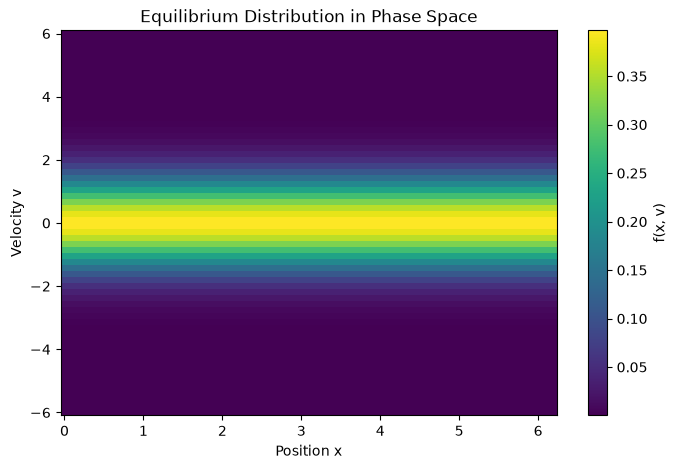

In [5]:
plt.figure(figsize=(8, 5))

plt.pcolormesh(
    x,
    v,
    f0_v.T,
    shading="auto"
)

plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title("Equilibrium Distribution in Phase Space")

plt.colorbar(label="f(x, v)")

plt.show()

In [6]:
# Landau-damping-style initial perturbation

alpha = 0.01       # Small perturbation amplitude
k = 1.0            # Spatial wavenumber

# Equilibrium Maxwellian
f_equilibrium = (1 / np.sqrt(2 * np.pi)) * np.exp(-V**2 / 2)

# Perturbed initial distribution
f_initial = f_equilibrium * (1 + alpha * np.cos(k * X))

print("Initial distribution shape:", f_initial.shape)
print("Minimum f:", f_initial.min())
print("Maximum f:", f_initial.max())

Initial distribution shape: (64, 64)
Minimum f: 6.015124021325053e-09
Maximum f: 0.4011084859468086


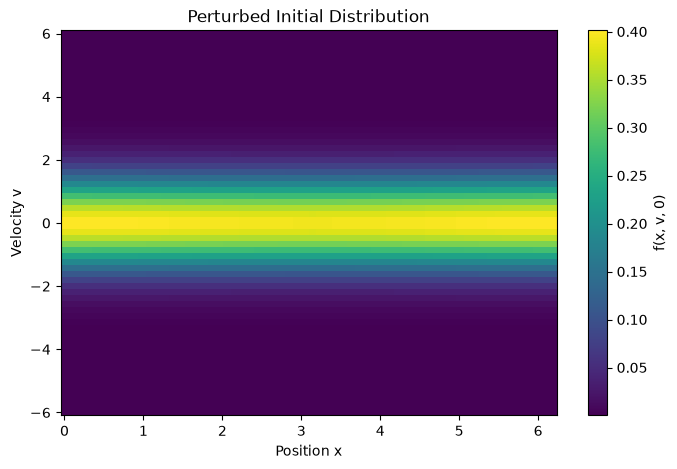

In [7]:
plt.figure(figsize=(8, 5))

plt.pcolormesh(
    x,
    v,
    f_initial.T,
    shading="auto"
)

plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title("Perturbed Initial Distribution")

plt.colorbar(label="f(x, v, 0)")

plt.show()

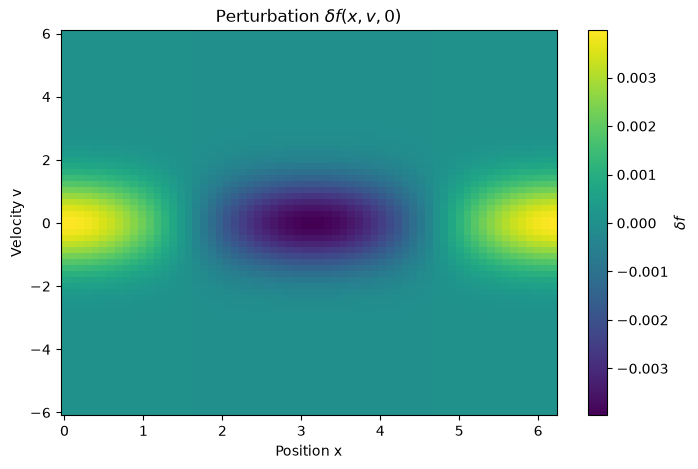

In [8]:
delta_f = f_initial - f_equilibrium

plt.figure(figsize=(8, 5))

plt.pcolormesh(
    x,
    v,
    delta_f.T,
    shading="auto"
)

plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title(r"Perturbation $\delta f(x,v,0)$")

plt.colorbar(label=r"$\delta f$")

plt.show()